MATH 550 HW 4

2026-09-30

In [ ]:
%pip install ISLP

I import the libraries used in the Chapter 4 lab.

In [2]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data, confusion_table
from ISLP.models import (ModelSpec as MS,
                         summarize)
from sklearn.discriminant_analysis import \
     (LinearDiscriminantAnalysis as LDA,
      QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

Exercise 6. a) Estimate the probability that a student who studies for 40 hours and has an undergrad GPA of 3.5 gets an A in the class.

$$
P(receive = A \mid X_1 = 40, X_2 = 3.5) = \frac{1}{1 + e^{-(-6 + 40 \cdot 0.05 + 3.5)}} = 0.3775407
$$

In [3]:
1 / (1 + np.exp(-(-6 + 40*0.05 + 1*3.5)))

np.float64(0.3775406687981454)

b) We want to know how many hours the student in part (a) would need to study to have a 50% chance of getting an A in the class.
$X_1$ is unknown: we want to find the $X_1$ s.t. the probability in point (a) is 0.5. Thus the $y$ s.t.

$$
\frac{1}{1+e^{-y}} = 0.5 \quad\Rightarrow\quad y = 0 .
$$

Thus

$$
-6 + 0.05 \cdot hours + 3.5 = 0 \Rightarrow hours = 50
$$

In [4]:
hours = (6 - 3.5) / 0.05
hours

50.0

Exercise 12.

a) The probability of classifying an observation $X = x$ as an orange in your logistic regression model is given by:

$$
\Pr(Y = \text{orange} \mid X = x) = \frac{\exp(\hat\beta_0 + \hat\beta_1 x)}{1 + \exp(\hat\beta_0 + \hat\beta_1 x)}
$$

The probability of classifying it as an apple is:

$$
\Pr(Y = \text{apple} \mid X = x) = 1 - \Pr(Y = \text{orange} \mid X = x) = \frac{1}{1 + \exp(\hat\beta_0 + \hat\beta_1 x)}
$$

The odds of orange versus apple are the ratio of these probabilities:

$$
\text{Odds} = \frac{\Pr(Y = \text{orange} \mid X = x)}{\Pr(Y = \text{apple} \mid X = x)} = \frac{\frac{\exp(\hat\beta_0 + \hat\beta_1 x)}{1 + \exp(\hat\beta_0 + \hat\beta_1 x)}}{\frac{1}{1 + \exp(\hat\beta_0 + \hat\beta_1 x)}} = \exp(\hat\beta_0 + \hat\beta_1 x)
$$

The log odds are the natural logarithm of the odds:

$$
\ln(\text{Odds}) = \ln(\exp(\hat\beta_0 + \hat\beta_1 x)) = \hat\beta_0 + \hat\beta_1 x
$$

b) Your friend's softmax formulation gives the probability of an orange as:

$$
\Pr(Y = \text{orange} \mid X = x) = \frac{\exp(\hat\alpha_{\text{orange}0} + \hat\alpha_{\text{orange}1} x)}{\exp(\hat\alpha_{\text{orange}0} + \hat\alpha_{\text{orange}1} x) + \exp(\hat\alpha_{\text{apple}0} + \hat\alpha_{\text{apple}1} x)}
$$

The probability of an apple is:

$$
\Pr(Y = \text{apple} \mid X = x) = \frac{\exp(\hat\alpha_{\text{apple}0} + \hat\alpha_{\text{apple}1} x)}{\exp(\hat\alpha_{\text{orange}0} + \hat\alpha_{\text{orange}1} x) + \exp(\hat\alpha_{\text{apple}0} + \hat\alpha_{\text{apple}1} x)}
$$

The odds of orange versus apple are:

$$
\text{Odds} = \frac{\exp(\hat\alpha_{\text{orange}0} + \hat\alpha_{\text{orange}1} x)}{\exp(\hat\alpha_{\text{apple}0} + \hat\alpha_{\text{apple}1} x)} = \exp\big((\hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0}) + (\hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1}) x\big)
$$

The log odds are:

$$
\ln(\text{Odds}) = (\hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0}) + (\hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1}) x
$$

c) For the two models to be equivalent, their log odds must be equal:

$$
\hat\beta_0 + \hat\beta_1 x = (\hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0}) + (\hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1}) x
$$

Given $\hat\beta_0 = 2$ and $\hat\beta_1 = -1$:

$$
2 = \hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0}, \qquad -1 = \hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1}
$$

Only the differences are determined, so we can specify a solution by setting one class's coefficients to zero. Let's set the coefficients for the apple class to zero:

$$
\hat\alpha_{\text{apple}0} = 0, \qquad \hat\alpha_{\text{apple}1} = 0
$$

Then we have:

$$
\hat\alpha_{\text{orange}0} = 2, \qquad \hat\alpha_{\text{orange}1} = -1
$$

The coefficient estimates for your friend's model are $\hat\alpha_{\text{orange}0} = 2$, $\hat\alpha_{\text{orange}1} = -1$, $\hat\alpha_{\text{apple}0} = 0$ and $\hat\alpha_{\text{apple}1} = 0$.

d) Given your friend's coefficients $\hat\alpha_{\text{orange}0} = 1.2$, $\hat\alpha_{\text{orange}1} = -2$, $\hat\alpha_{\text{apple}0} = 3$ and $\hat\alpha_{\text{apple}1} = 0.6$, using the relationships derived in part (c):

$$
\hat\beta_0 = \hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0} = 1.2 - 3 = -1.8
$$

$$
\hat\beta_1 = \hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1} = -2 - 0.6 = -2.6
$$

In [5]:
beta0 = 1.2 - 3
beta1 = -2 - 0.6
beta0, beta1

(-1.8, -2.6)

e) The predicted class label is determined by which class has the higher probability. This is equivalent to checking the sign of the log odds.

$$
\text{Predict orange if } \ln(\text{Odds}) > 0 \implies \text{Predict orange if } \hat\beta_0 + \hat\beta_1 x > 0
$$

$$
\text{Predict apple if } \ln(\text{Odds}) < 0 \implies \text{Predict apple if } \hat\beta_0 + \hat\beta_1 x < 0
$$

As shown in part (d), the log odds from your friend's model, $(\hat\alpha_{\text{orange}0} - \hat\alpha_{\text{apple}0}) + (\hat\alpha_{\text{orange}1} - \hat\alpha_{\text{apple}1})x$, are identical to your model's log odds, $\hat\beta_0 + \hat\beta_1 x$.
Therefore, both models will make the same classification decision for every single observation. The predicted class labels from your model will agree with those from your friend's model 100% of the time, i.e. on all 2,000 test observations.

I check it with 2,000 simulated test observations:

In [6]:
x = np.random.default_rng(1).normal(size=2000)
p_mine = np.exp(beta0 + beta1*x) / (1 + np.exp(beta0 + beta1*x))
p_friend = np.exp(1.2 - 2*x) / (np.exp(1.2 - 2*x) + np.exp(3 + 0.6*x))
np.mean((p_mine > 0.5) == (p_friend > 0.5))

np.float64(1.0)

Exercise 13. I import the dataset

In [7]:
Weekly = load_data('Weekly')
Weekly

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,1990,0.816,1.572,-3.936,-0.229,-3.484,0.154976,-0.270,Down
1,1990,-0.270,0.816,1.572,-3.936,-0.229,0.148574,-2.576,Down
2,1990,-2.576,-0.270,0.816,1.572,-3.936,0.159837,3.514,Up
3,1990,3.514,-2.576,-0.270,0.816,1.572,0.161630,0.712,Up
4,1990,0.712,3.514,-2.576,-0.270,0.816,0.153728,1.178,Up
...,...,...,...,...,...,...,...,...,...
1084,2010,-0.861,0.043,-2.173,3.599,0.015,3.205160,2.969,Up
1085,2010,2.969,-0.861,0.043,-2.173,3.599,4.242568,1.281,Up
1086,2010,1.281,2.969,-0.861,0.043,-2.173,4.835082,0.283,Up
1087,2010,0.283,1.281,2.969,-0.861,0.043,4.454044,1.034,Up


a) We do a scatterplot matrix, here we can notice a correlation mostly between 'Volume' and 'Year'

In [8]:
Weekly.describe()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
count,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000,1089.000000
mean,2000.048669,0.150585,0.151079,0.147205,0.145818,0.139893,1.574618,0.149899
std,6.033182,2.357013,2.357254,2.360502,2.360279,2.361285,1.686636,2.356927
min,1990.000000,-18.195000,-18.195000,-18.195000,-18.195000,-18.195000,0.087465,-18.195000
25%,1995.000000,-1.154000,-1.154000,-1.158000,-1.158000,-1.166000,0.332022,-1.154000
50%,2000.000000,0.241000,0.241000,0.241000,0.238000,0.234000,1.002680,0.241000
75%,2005.000000,1.405000,1.409000,1.409000,1.409000,1.405000,2.053727,1.405000
max,2010.000000,12.026000,12.026000,12.026000,12.026000,12.026000,9.328214,12.026000


In [9]:
Weekly['Direction'].value_counts()

Direction
Up      605
Down    484
Name: count, dtype: int64

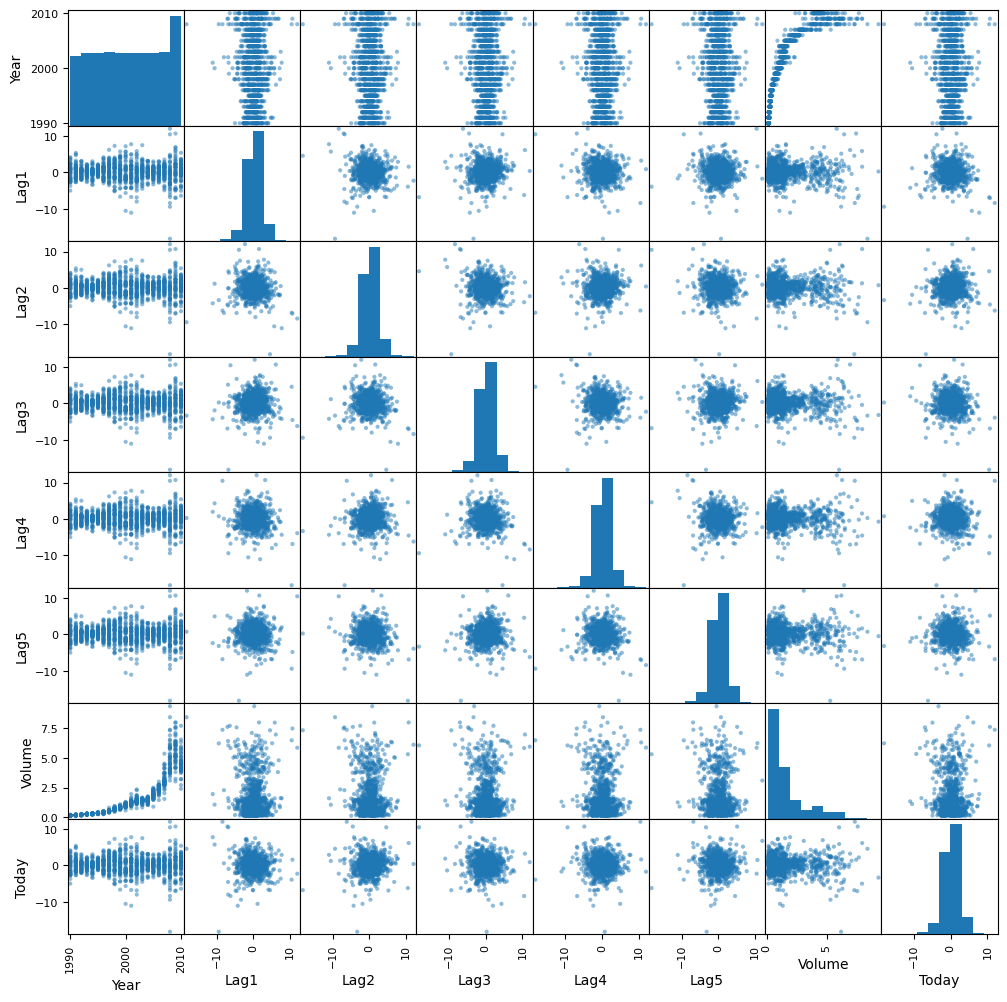

In [10]:
pd.plotting.scatter_matrix(Weekly, figsize=(12, 12));

we look at the correlations

In [11]:
Weekly.drop(columns=['Direction']).corr()

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,-0.032289,-0.033390,-0.030006,-0.031128,-0.030519,0.841942,-0.032460
Lag1,-0.032289,1.000000,-0.074853,0.058636,-0.071274,-0.008183,-0.064951,-0.075032
Lag2,-0.033390,-0.074853,1.000000,-0.075721,0.058382,-0.072499,-0.085513,0.059167
Lag3,-0.030006,0.058636,-0.075721,1.000000,-0.075396,0.060657,-0.069288,-0.071244
Lag4,-0.031128,-0.071274,0.058382,-0.075396,1.000000,-0.075675,-0.061075,-0.007826
Lag5,-0.030519,-0.008183,-0.072499,0.060657,-0.075675,1.000000,-0.058517,0.011013
Volume,0.841942,-0.064951,-0.085513,-0.069288,-0.061075,-0.058517,1.000000,-0.033078
Today,-0.032460,-0.075032,0.059167,-0.071244,-0.007826,0.011013,-0.033078,1.000000


We can plot also the following graph where it is clear that the 'Volume' increases as the years go on.

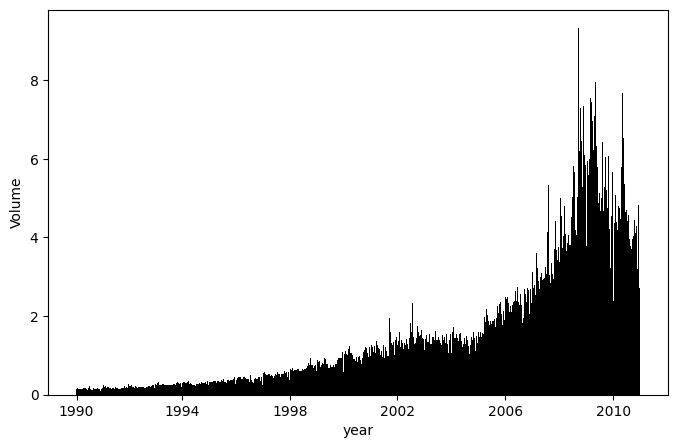

In [12]:
fig, ax = subplots(figsize=(8, 5))
ax.bar(Weekly.index, Weekly['Volume'], width=1, color='k')
ax.set_xticks(Weekly.groupby('Year').head(1).index[::4])
ax.set_xticklabels(Weekly['Year'].unique()[::4])
ax.set_xlabel('year')
ax.set_ylabel('Volume');

b) Perform a logistic regression

In [13]:
allvars = Weekly.columns.drop(['Today', 'Direction', 'Year'])
design = MS(allvars)
X = design.fit_transform(Weekly)
y = Weekly.Direction == 'Up'
Weekly_fits = sm.GLM(y, X, family=sm.families.Binomial()).fit()
Weekly_fits.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                 Generalized Linear Model Regression Results                  
==============================================================================
Dep. Variable:              Direction   No. Observations:                 1089
Model:                            GLM   Df Residuals:                     1082
Model Family:                Binomial   Df Model:                            6
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -743.18
Date:                Wed, 30 Sep 2026   Deviance:                       1486.4
Time:                        11:44:00   Pearson chi2:                 1.09e+03
No. Iterations:                     4   Pseudo R-squ. (CS):           0.009000
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.2669      0.086      3.106      0.002       0.098       0.435
Lag1          -0.0413      0.026     -1.563      0.118      -0.093       0.010
Lag2           0.0584      0.027      2.175      0.030       0.006       0.111
Lag3          -0.0161      0.027     -0.602      0.547      -0.068       0.036
Lag4          -0.0278      0.026     -1.050      0.294      -0.080       0.024
Lag5          -0.0145      0.026     -0.549      0.583      -0.066       0.037
Volume        -0.0227      0.037     -0.616      0.538      -0.095       0.050
==============================================================================
"""

Among all the predictors 'Lag2' is statistically significant because its z-score is positive and its p-value is less than 0.05; for all the other predictors it is more than 0.05, so their effect is almost null.

c) Compute the confusion matrix and overall fraction of correct predictions:

In [14]:
weekly_probs = Weekly_fits.predict()
weekly_pred = np.array(['Down'] * 1089)
weekly_pred[weekly_probs > 0.5] = 'Up'
confusion_table(weekly_pred, Weekly.Direction)

Truth,Down,Up
Predicted,,
Down,54,48
Up,430,557


In [15]:
(54 + 557) / 1089

0.5610651974288338

In [16]:
np.mean(weekly_pred == Weekly.Direction)

np.float64(0.5610651974288338)

This means that the logistic regression correctly predicts the movement of the market 56.1% of the time.

In [17]:
557 / (557 + 48)

0.9206611570247933

In [18]:
54 / (54 + 430)

0.1115702479338843

We correctly predicted when the trend would go up 92.07% of the time, while only correctly predicting when it would go down 11.16% of the time.
So most of the mistakes are weeks that go down but are predicted as up.

d) Fit the logistic regression model using a training data period from 1990 to 2008 with 'Lag2' as the only predictor

In [19]:
train = (Weekly.Year < 2009)
Weekly_2009 = Weekly.loc[~train]
Weekly_2009.shape

(104, 9)

In [20]:
X = MS(['Lag2']).fit_transform(Weekly)
X_train, X_test = X.loc[train], X.loc[~train]
y_train = y.loc[train]
Direction_train = Weekly.Direction.loc[train]
Direction_2009 = Weekly.Direction.loc[~train]

Weekly_fits = sm.GLM(y_train, X_train, family=sm.families.Binomial()).fit()
Weekly_prob = Weekly_fits.predict(exog=X_test)
Weekly_pred = np.array(['Down'] * len(Weekly_prob))
Weekly_pred[Weekly_prob > 0.5] = 'Up'
confusion_table(Weekly_pred, Direction_2009)

Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


We see that the model accurately predicted the outcome 62.5% of the time.

In [21]:
(9 + 56) / 104

0.625

In [22]:
np.mean(Weekly_pred == Direction_2009)

np.float64(0.625)

And it also correctly predicted the trend would go up 91.80% of the time and correctly predicted the trend would go down 20.93% of the time, which is a slight improvement from the previous model.

In [23]:
56 / (56 + 5)

0.9180327868852459

In [24]:
9 / (9 + 34)

0.20930232558139536

e) Repeat with LDA. As in the lab, we drop the intercept column since `sklearn` adds it itself.

In [25]:
X_train, X_test = [M.drop(columns=['intercept']) for M in [X_train, X_test]]
Weeklylda_fit = LDA(store_covariance=True)
Weeklylda_fit.fit(X_train, Direction_train)
Weeklylda_fit.classes_, Weeklylda_fit.priors_

(array(['Down', 'Up'], dtype='<U4'), array([0.44771574, 0.55228426]))

In [26]:
Weeklylda_fit.means_

array([[-0.03568254],
       [ 0.26036581]])

In [27]:
Weeklylda_fit.scalings_

array([[0.44141622]])

In [28]:
Weeklylda_pred = Weeklylda_fit.predict(X_test)
confusion_table(Weeklylda_pred, Direction_2009)

Truth,Down,Up
Predicted,,
Down,9,5
Up,34,56


In [29]:
(9 + 56) / 104

0.625

In [30]:
np.mean(Weeklylda_pred == Direction_2009)

np.float64(0.625)

In [31]:
56 / (56 + 5)

0.9180327868852459

In [32]:
9 / (9 + 34)

0.20930232558139536

Using LDA gave exactly the same results as the logistic regression model created in part (d), with an accuracy of 62.5%. It correctly predicts the trend would go up 91.80% of the time and correctly predicts the trend would go down 20.93% of the time.

f) Repeat using QDA

In [33]:
Weeklyqda_fit = QDA(store_covariance=True)
Weeklyqda_fit.fit(X_train, Direction_train)
Weeklyqda_pred = Weeklyqda_fit.predict(X_test)
confusion_table(Weeklyqda_pred, Direction_2009)

Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


In [34]:
(0 + 61) / 104

0.5865384615384616

In [35]:
np.mean(Weeklyqda_pred == Direction_2009)

np.float64(0.5865384615384616)

The model predicted correctly 58.65% of the time.

In [36]:
0 / 43

0.0

In [37]:
61 / 61

1.0

So this model does not predict the downward trend at all, but it is 100% accurate at predicting when it will go up, because it always predicts 'Up'.

g) Repeat using KNN with K=1.

In [38]:
Weekknn = KNeighborsClassifier(n_neighbors=1)
Weekknn.fit(X_train, Direction_train)
Weekknn_pred = Weekknn.predict(X_test)
confusion_table(Weekknn_pred, Direction_2009)

Truth,Down,Up
Predicted,,
Down,22,32
Up,21,29


In [39]:
(22 + 29) / 104

0.49038461538461536

In [40]:
np.mean(Weekknn_pred == Direction_2009)

np.float64(0.49038461538461536)

This model lowered the accuracy to only 49%.

In [41]:
29 / (32 + 29)

0.47540983606557374

In [42]:
22 / (22 + 21)

0.5116279069767442

It correctly predicts the trend would go up 47.54% of the time and correctly predicts the trend would go down 51.16% of the time.

h) Repeat using naive Bayes.

In [43]:
weeklynb_fit = GaussianNB()
weeklynb_fit.fit(X_train, Direction_train)
weeklynb_fit.classes_, weeklynb_fit.class_prior_

(array(['Down', 'Up'], dtype='<U4'), array([0.44771574, 0.55228426]))

The means and standard deviations of 'Lag2' in each class:

In [44]:
weeklynb_fit.theta_, np.sqrt(weeklynb_fit.var_)

(array([[-0.03568254],
        [ 0.26036581]]),
 array([[2.19700876],
        [2.31535444]]))

In [45]:
weeklynb_class = weeklynb_fit.predict(X_test)
confusion_table(weeklynb_class, Direction_2009)

Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


In [46]:
np.mean(weeklynb_class == Direction_2009)

np.float64(0.5865384615384616)

It produced exactly the same results as the QDA model we fit in part (f). Both models had an accuracy of 58.65%.

i) The logistic regression model and LDA appear to provide the best results, being able to correctly predict the outcome 62.5% of the time.

j) After creating a model using KNN with K=20, we are able to increase the accuracy to 59.62%, which is an improvement compared to K=1.

In [47]:
Weekknn2 = KNeighborsClassifier(n_neighbors=20)
Weekknn2.fit(X_train, Direction_train)
Weekknn_pred2 = Weekknn2.predict(X_test)
confusion_table(Weekknn_pred2, Direction_2009)

Truth,Down,Up
Predicted,,
Down,23,22
Up,20,39


In [48]:
np.mean(Weekknn_pred2 == Direction_2009)

np.float64(0.5961538461538461)

This LDA model with Lag2:Lag3 as the predictor gave us an accuracy of 58.65%, which is lower than the previous LDA model created in part (e).

In [49]:
X2 = MS([('Lag2', 'Lag3')], intercept=False).fit_transform(Weekly)
Weeklylda_fit2 = LDA(store_covariance=True)
Weeklylda_fit2.fit(X2.loc[train], Direction_train)
Weeklylda_pred2 = Weeklylda_fit2.predict(X2.loc[~train])
confusion_table(Weeklylda_pred2, Direction_2009)

Truth,Down,Up
Predicted,,
Down,0,0
Up,43,61


In [50]:
np.mean(Weeklylda_pred2 == Direction_2009)

np.float64(0.5865384615384616)

Finally, a QDA model with 'Lag2' and 'Lag2' squared gave an accuracy of 62.5%, the same as the best models in (d) and (e) and better than the QDA in (f).

In [51]:
X3 = pd.DataFrame({'Lag2': Weekly.Lag2, 'Lag2_sq': Weekly.Lag2**2})
Weeklyqda_fit2 = QDA(store_covariance=True)
Weeklyqda_fit2.fit(X3.loc[train], Direction_train)
Weeklyqda_pred2 = Weeklyqda_fit2.predict(X3.loc[~train])
confusion_table(Weeklyqda_pred2, Direction_2009)

Truth,Down,Up
Predicted,,
Down,7,3
Up,36,58


In [52]:
np.mean(Weeklyqda_pred2 == Direction_2009)

np.float64(0.625)

So the best results on the held-out data are logistic regression and LDA with 'Lag2' only, with 62.5% accuracy and confusion matrix

| | Down | Up |
|---|---|---|
| Down | 9 | 5 |
| Up | 34 | 56 |

Exercise 16.

I load the dataset 'Boston'

In [53]:
Boston = load_data('Boston')
Boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,6.48,22.0


a) I create the response variable 'Crime', equal to 1 if the crime rate is above the median and 0 otherwise.

In [54]:
Crime = np.zeros(len(Boston['crim']), dtype=int)
Crime[Boston['crim'] > Boston['crim'].median()] = 1
Boston01 = Boston.assign(Crime=Crime)

b) I use the first half of the data as the training set and the second half as the test set.

In [55]:
n = Boston01.shape[0]
train = np.arange(n // 2)
test = np.arange(n // 2, n)
Boston_train = Boston01.iloc[train]
Boston_test = Boston01.iloc[test]
Crime_train = Crime[train]
Crime_test = Crime[test]
Boston01.corr()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv,Crime
crim,1.000000,-0.200469,0.406583,-0.055892,0.420972,-0.219247,0.352734,-0.379670,0.625505,0.582764,0.289946,0.455621,-0.388305,0.409395
zn,-0.200469,1.000000,-0.533828,-0.042697,-0.516604,0.311991,-0.569537,0.664408,-0.311948,-0.314563,-0.391679,-0.412995,0.360445,-0.436151
indus,0.406583,-0.533828,1.000000,0.062938,0.763651,-0.391676,0.644779,-0.708027,0.595129,0.720760,0.383248,0.603800,-0.483725,0.603260
chas,-0.055892,-0.042697,0.062938,1.000000,0.091203,0.091251,0.086518,-0.099176,-0.007368,-0.035587,-0.121515,-0.053929,0.175260,0.070097
nox,0.420972,-0.516604,0.763651,0.091203,1.000000,-0.302188,0.731470,-0.769230,0.611441,0.668023,0.188933,0.590879,-0.427321,0.723235
rm,-0.219247,0.311991,-0.391676,0.091251,-0.302188,1.000000,-0.240265,0.205246,-0.209847,-0.292048,-0.355501,-0.613808,0.695360,-0.156372
age,0.352734,-0.569537,0.644779,0.086518,0.731470,-0.240265,1.000000,-0.747881,0.456022,0.506456,0.261515,0.602339,-0.376955,0.613940
dis,-0.379670,0.664408,-0.708027,-0.099176,-0.769230,0.205246,-0.747881,1.000000,-0.494588,-0.534432,-0.232471,-0.496996,0.249929,-0.616342
rad,0.625505,-0.311948,0.595129,-0.007368,0.611441,-0.209847,0.456022,-0.494588,1.000000,0.910228,0.464741,0.488676,-0.381626,0.619786
tax,0.582764,-0.314563,0.720760,-0.035587,0.668023,-0.292048,0.506456,-0.534432,0.910228,1.000000,0.460853,0.543993,-0.468536,0.608741


In [56]:
Boston01.corr()['Crime'].sort_values()

dis       -0.616342
zn        -0.436151
medv      -0.263017
rm        -0.156372
chas       0.070097
ptratio    0.253568
crim       0.409395
lstat      0.453263
indus      0.603260
tax        0.608741
age        0.613940
rad        0.619786
nox        0.723235
Crime      1.000000
Name: Crime, dtype: float64

The variables most correlated with 'Crime' are 'nox', 'rad', 'dis', 'age', 'tax' and 'indus'.

c) Now we use the logistic regression model with the predictor variables 'nox', 'rad', 'tax', 'indus' and 'chas':

In [57]:
vars = ['nox', 'rad', 'tax', 'indus', 'chas']
design = MS(vars)
X_train = design.fit_transform(Boston_train)
X_test = design.transform(Boston_test)
glm_bostonfit = sm.GLM(Crime_train, X_train, family=sm.families.Binomial()).fit()
Boston_probs = glm_bostonfit.predict(exog=X_test)
len(Boston_probs)

253

In [58]:
Boston_pred = np.zeros(len(Boston_probs), dtype=int)
Boston_pred[Boston_probs > 0.5] = 1
confusion_table(Boston_pred, Crime_test)

Truth,0,1
Predicted,,
0,75,6
1,15,157


In [59]:
(75 + 157) / 253

0.9169960474308301

In [60]:
np.mean(Boston_pred == Crime_test)

np.float64(0.9169960474308301)

We got an accuracy of 91.70%.

d) Now we use the Linear Discriminant Analysis model

In [61]:
lda_bostonfit = LDA(store_covariance=True)
lda_bostonfit.fit(Boston_train[vars], Crime_train)
Bostonlda_pred = lda_bostonfit.predict(Boston_test[vars])
confusion_table(Bostonlda_pred, Crime_test)

Truth,0,1
Predicted,,
0,80,18
1,10,145


In [62]:
(80 + 145) / 253

0.8893280632411067

In [63]:
np.mean(Bostonlda_pred == Crime_test)

np.float64(0.8893280632411067)

We got an accuracy of 88.93%, which is lower than the logistic regression model.

e) Now we use the naive Bayes model with the same predictors

In [64]:
nb_bostonfit = GaussianNB()
nb_bostonfit.fit(Boston_train[vars], Crime_train)
Bostonnb_pred = nb_bostonfit.predict(Boston_test[vars])
confusion_table(Bostonnb_pred, Crime_test)

Truth,0,1
Predicted,,
0,73,18
1,17,145


In [65]:
(73 + 145) / 253

0.8616600790513834

In [66]:
np.mean(Bostonnb_pred == Crime_test)

np.float64(0.8616600790513834)

We got an accuracy of 86.17%, a bit lower than LDA. This is expected, since naive Bayes assumes the predictors are independent within each class, while 'nox', 'tax' and 'indus' are strongly correlated.

f) Now we use the QDA model with 'nox', 'rad', 'tax' and 'indus'

In [67]:
qda_vars = ['nox', 'rad', 'tax', 'indus']
qda_bostonfit = QDA(store_covariance=True)
qda_bostonfit.fit(Boston_train[qda_vars], Crime_train)
Bostonqda_pred = qda_bostonfit.predict(Boston_test[qda_vars])
confusion_table(Bostonqda_pred, Crime_test)

Truth,0,1
Predicted,,
0,81,148
1,9,15


In [68]:
(81 + 15) / 253

0.3794466403162055

In [69]:
np.mean(Bostonqda_pred == Crime_test)

np.float64(0.3794466403162055)

The QDA model gives an accuracy of only 37.94%, which is extremely low. In the training set 'rad' takes very few distinct values within each class, so the class covariance matrices are almost singular and QDA is unstable.
Adding the interactions nox:rad and indus:chas (as in `nox*rad + tax + indus*chas`) makes the covariance matrix singular, so I add a small regularization (`reg_param=0.01`):

In [70]:
design_qda = MS(['nox', 'rad', ('nox', 'rad'), 'tax', 'indus', 'chas', ('indus', 'chas')],
                intercept=False)
Q_train = design_qda.fit_transform(Boston_train)
Q_test = design_qda.transform(Boston_test)
qda_bostonfit2 = QDA(reg_param=0.01)
qda_bostonfit2.fit(Q_train, Crime_train)
Bostonqda_pred2 = qda_bostonfit2.predict(Q_test)
confusion_table(Bostonqda_pred2, Crime_test)

Truth,0,1
Predicted,,
0,78,21
1,12,142


In [71]:
np.mean(Bostonqda_pred2 == Crime_test)

np.float64(0.8695652173913043)

Now the accuracy is 86.96%, much better, but still lower than logistic regression and LDA.

g) Now we use the KNN model, with the variables 'indus', 'nox', 'age', 'dis', 'rad' and 'tax' and K=10

In [72]:
knn_vars = ['indus', 'nox', 'age', 'dis', 'rad', 'tax']
train_knn = Boston_train[knn_vars]
test_knn = Boston_test[knn_vars]
Bostonknn = KNeighborsClassifier(n_neighbors=10)
Bostonknn.fit(train_knn, Crime_train)
Bostonknn_pred = Bostonknn.predict(test_knn)
confusion_table(Bostonknn_pred, Crime_test)

Truth,0,1
Predicted,,
0,83,23
1,7,140


In [73]:
(83 + 140) / 253

0.8814229249011858

In [74]:
np.mean(Bostonknn_pred == Crime_test)

np.float64(0.8814229249011858)

We got an accuracy of 88.14%, about the same as LDA. We also try KNN with K=1, which is much worse (37.15%) because it overfits:

In [75]:
Bostonknn1 = KNeighborsClassifier(n_neighbors=1)
Bostonknn1.fit(train_knn, Crime_train)
np.mean(Bostonknn1.predict(test_knn) == Crime_test)

np.float64(0.3715415019762846)

Finally, KNN with only 'nox' and 'rad' and K=10:

In [76]:
Bostonknn2 = KNeighborsClassifier(n_neighbors=10)
Bostonknn2.fit(Boston_train[['nox', 'rad']], Crime_train)
Bostonknn_pred2 = Bostonknn2.predict(Boston_test[['nox', 'rad']])
confusion_table(Bostonknn_pred2, Crime_test)

Truth,0,1
Predicted,,
0,83,9
1,7,154


In [77]:
np.mean(Bostonknn_pred2 == Crime_test)

np.float64(0.9367588932806324)

This gives the best accuracy, 93.68%.

h) In summary:

| Model | Predictors | Accuracy |
|---|---|---|
| Logistic regression | nox, rad, tax, indus, chas | 91.70% |
| LDA | nox, rad, tax, indus, chas | 88.93% |
| Naive Bayes | nox, rad, tax, indus, chas | 86.17% |
| QDA | nox, rad, tax, indus | 37.94% |
| QDA (regularized) | nox\*rad + tax + indus\*chas | 86.96% |
| KNN, K=10 | indus, nox, age, dis, rad, tax | 88.14% |
| KNN, K=1 | indus, nox, age, dis, rad, tax | 37.15% |
| KNN, K=10 | nox, rad | 93.68% |

The best models are KNN with 'nox' and 'rad' (93.68%) and logistic regression (91.70%). LDA and naive Bayes are a little worse, and QDA is very unstable on this data.
'nox' and 'rad' are the most important predictors: they alone are enough for a very good classification.